# Phase 5 : SHAP (SHapley Additive exPlanations)

In [19]:
import json
import os
import joblib
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# 1. 정형 데이터 및 타겟 로드
df_tabular = pd.read_parquet("./데이터/ml_tabular_features_clean.parquet")
y = np.load("./데이터/churn_labels_clean.npy")

# 2. 시퀀스 테스트 데이터 로드 (Phase 4에서 평가 폴더에 저장한 시퀀스 활용)
X_seq_test = np.load("./평가/X_test_sequence.npy")
y_true = np.load("./평가/test_y_true.npy")

# 3. LightGBM 모델 로드
lgb_model = joblib.load("./모델/lgb_model.pkl")

# 4. PyTorch LSTM 모델 구조 정의 및 가중치 로드
class ChurnLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim=1, dropout=0.3):
        super(ChurnLSTM, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(
            embedding_dim, 
            hidden_dim, 
            batch_first=True, 
            dropout=dropout, 
            num_layers=2
        )
        self.fc = nn.Linear(hidden_dim, output_dim)
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, x):
        embedded = self.embedding(x)
        out, (hn, cn) = self.lstm(embedded)
        out = self.dropout(hn[-1])
        out = self.fc(out)
        return out

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
lstm_model = ChurnLSTM(vocab_size=50, embedding_dim=32, hidden_dim=64).to(device)
lstm_model.load_state_dict(torch.load("./모델/lstm_model_weights.pth", map_location=device))
lstm_model.eval()

print("모든 모델과 데이터가 성공적으로 로드되었습니다!")

모든 모델과 데이터가 성공적으로 로드되었습니다!


c:\Users\playdata2\miniconda3\envs\agent\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


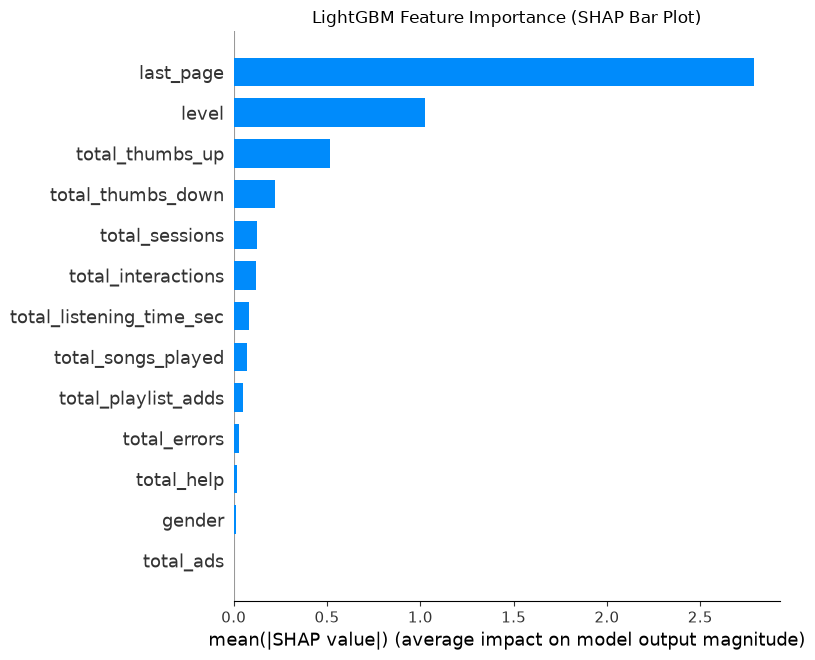

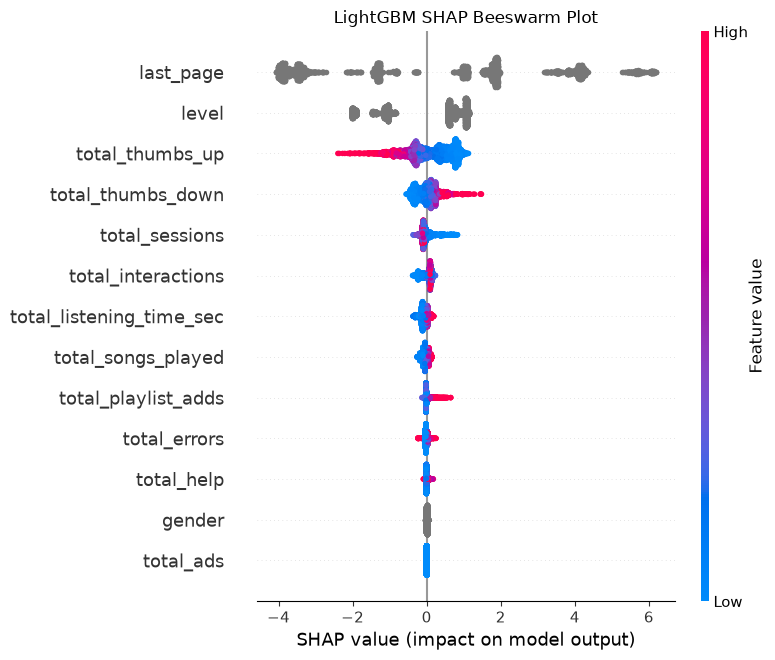

In [20]:
from sklearn.model_selection import train_test_split

# 1. Phase 4와 동일한 분할 인덱스 적용 (Test 세트 추출)
drop_cols = ["userId", "is_churn", "session_item_sequence", "page_sequence", "padded_sequence"]
X = df_tabular.drop(columns=[col for col in drop_cols if col in df_tabular.columns])

# 범주형 변수 타입 설정
cat_cols = ["gender", "level", "last_page"]
for col in cat_cols:
    if col in X.columns:
        X[col] = X[col].astype("category")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. TreeExplainer 생성 및 SHAP 값 계산
explainer_lgb = shap.TreeExplainer(lgb_model)
shap_values_lgb = explainer_lgb.shap_values(X_test)

# 이진 분류의 경우 shap_values가 리스트로 반환될 수 있으므로 양성 클래스 선택
if isinstance(shap_values_lgb, list):
    shap_vals_lgb_pos = shap_values_lgb[1]
else:
    shap_vals_lgb_pos = shap_values_lgb

# 3. 글로벌 중요도 요약 플롯 (Summary Bar Plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_lgb_pos, X_test, plot_type="bar", show=False)
plt.title("LightGBM Feature Importance (SHAP Bar Plot)")
plt.tight_layout()
plt.show()

# 4. 상세 영향력 분포 플롯 (Beeswarm Plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_lgb_pos, X_test, show=False)
plt.title("LightGBM SHAP Beeswarm Plot")
plt.tight_layout()
plt.show()

In [23]:
import torch
import torch.nn as nn
import numpy as np
import shap

# 1. Embedding 레이어 이후의 연산을 수행하는 래퍼 모델 정의
class LSTMWithoutEmbedding(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.lstm = model.lstm
        self.dropout = model.dropout
        self.fc = model.fc
        
    def forward(self, embedded_x):
        # embedded_x는 이미 Embedding을 거친 실수형(float) 텐서입니다.
        out, (hn, cn) = self.lstm(embedded_x)
        out = self.dropout(hn[-1])
        out = self.fc(out)
        return torch.sigmoid(out)

# 2. 기존 LSTM 모델을 래퍼로 감싸기
eval_model = LSTMWithoutEmbedding(lstm_model).to(device)
eval_model.eval()

# 3. 정수형 시퀀스 데이터를 Embedding 레이어에 통과시켜 실수형(float) 텐서로 변환
# (연산량과 메모리를 고려해 배경 데이터 100개, 평가 데이터 300개 사용)
with torch.no_grad():
    background_tokens = torch.tensor(X_seq_test[:100], dtype=torch.long).to(device)
    test_eval_tokens = torch.tensor(X_seq_test[:300], dtype=torch.long).to(device)
    
    background_emb = lstm_model.embedding(background_tokens)
    test_eval_emb = lstm_model.embedding(test_eval_tokens)

# 4. 실수형 임베딩 텐서를 바탕으로 DeepExplainer 실행
# 4. 실수형 임베딩 텐서를 바탕으로 DeepExplainer 실행
explainer_lstm = shap.DeepExplainer(eval_model, background_emb)

# 💡 check_additivity=False 옵션을 추가하여 엄격한 수식 합산 검증을 건너뜁니다.
shap_values_lstm = explainer_lstm.shap_values(test_eval_emb, check_additivity=False)

print(f"LSTM SHAP 값 계산 완료! Shape: {np.array(shap_values_lstm).shape}")

LSTM SHAP 값 계산 완료! Shape: (300, 50, 32, 1)


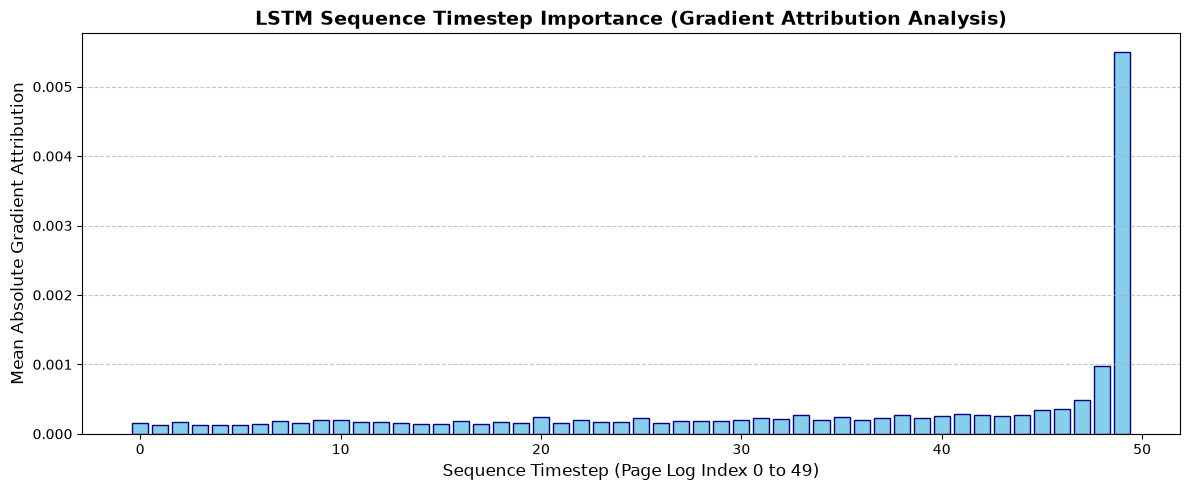

LSTM 시퀀스 그래디언트 분석 및 시각화가 에러 없이 성공적으로 완료되었습니다!


In [30]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# 1. Embedding 레이어 이후의 연산을 수행하는 래퍼 모델 정의
class LSTMWithoutEmbedding(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.lstm = model.lstm
        self.dropout = model.dropout
        self.fc = model.fc
        
    def forward(self, embedded_x):
        out, (hn, cn) = self.lstm(embedded_x)
        out = self.dropout(hn[-1])
        out = self.fc(out)
        return torch.sigmoid(out)

eval_model = LSTMWithoutEmbedding(lstm_model).to(device)
eval_model.eval()

# 2. 테스트 시퀀스 데이터를 임베딩 텐서로 변환하고 그라디언트 추적 활성화
test_eval_tokens = torch.tensor(X_seq_test[:300], dtype=torch.long).to(device)

with torch.no_grad():
    test_eval_emb = lstm_model.embedding(test_eval_tokens).clone().detach()

# 미분 계산을 위해 requires_grad를 True로 설정
test_eval_emb.requires_grad_(True)

# 3. 순전파 실행
outputs = eval_model(test_eval_emb)

# 4. 역전파(Gradient) 계산 (출력값의 합에 대한 입력 임베딩의 민감도 측정)
eval_model.zero_grad()
loss = outputs.sum()
loss.backward()

# 5. Input * Gradient 방식으로 각 타임스텝 및 피처별 영향력 계산
gradients = test_eval_emb.grad.detach().cpu().numpy()  # shape: (300, 50, 32)
embeddings = test_eval_emb.detach().cpu().numpy()      # shape: (300, 50, 32)

# 입력값과 그라디언트를 곱한 뒤 절대값을 취해 기여도(Attribution) 산출
attribution = np.abs(embeddings * gradients)

# 샘플 축(0)과 임베딩 차원 축(2)을 평균내어, 각 타임스텝(0~49)별 평균 중요도 도출
mean_importance_per_timestep = np.mean(attribution, axis=(0, 2))

# 6. Matplotlib 바 차트 시각화
plt.figure(figsize=(12, 5))
plt.bar(range(len(mean_importance_per_timestep)), mean_importance_per_timestep, color='skyblue', edgecolor='navy')
plt.xlabel("Sequence Timestep (Page Log Index 0 to 49)", fontsize=12)
plt.ylabel("Mean Absolute Gradient Attribution", fontsize=12)
plt.title("LSTM Sequence Timestep Importance (Gradient Attribution Analysis)", fontsize=14, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("LSTM 시퀀스 그래디언트 분석 및 시각화가 에러 없이 성공적으로 완료되었습니다!")